# Introduction

In part 1 of this assessment, you will complete several requested SQL queries in order to extract data, analyze, and provide insights from a single provided SQL database. You will also visualize the key results of 3 of these queries. There are also several 'Reflection' questions that ask you to write out a text based answer in the provided markdown cell. Following the guided question and answer section, in part 2 you will explore a second dataset on your own using SQL in order to conduct a preliminary analysis. You will be asked to produce a very short slide presentation highlighting the work you did for this second section.

## Objectives
You will be able to:
- Interpret "word problems" and translate them into SQL queries
- Decide and perform whichever type of JOIN is best for retrieving desired data
- Use GROUP BY statements to apply aggregate functions like COUNT, MAX, MIN, and SUM
- Use the HAVING clause to compare different aggregates
- Write subqueries to decompose complex queries
- Visualize data using matplotlib, seaborn, or pandas
- Choose the correct chart type based on the given data


## Part 1: Guided SQL Queries

### Your Task: Querying a Customer Database

![toy car picture](images/toycars.jpg)


### Business Understanding
Your employer sells wholesale miniature models of products such as classic cars, motorcycles, and planes. They want you to pull several reports on different segments of their past customers, in order to better understand past sales as well as determine which customers will receive promotional material. They are also interested in investigating which products have performed the best, as well as having several smaller asks.

In addition to providing the requested data from the SQL database you have also been asked to create some basic visuals to display some of the more insightful information. It is up to your discretion to choose the correct plot/chart type for the data in question. **Questions that want you to visualize the results will be explicitly marked**.

### Data Understanding
You may remember this database from a previous lab. As a refresher, here's the ERD diagram for this database:

![ERD picture](images/ERD.png)

The queries you are asked to write will become more complex over the course of the lab.



### Getting Started
For this assessment you are expected to make use of both sqlite3 and the Pandas libraries in order to write, execute, and return SQL queries as a Pandas DataFrame. Assign each returned answer as its own explicit variable.

For the visualization piece you are expected to utilize either Pandas, Seaborn, or Matplotlib to create your visuals. Make sure you are providing verbose labels and titles according to the data you are being asked to visualize. Do not worry too much about choosing a 'style' or 'context' instead focus on conveying the requested information correctly.

### Step 1: Connect to Data

In the cell below
- Import the necessary libraries
- Establish a connection to the database data.sqlite

In [78]:
# Replace None with your code
# Imports
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline



# Create connection to database
conn = sqlite3.connect("data.sqlite")



### Step 2: Limited Edition California Product
The California sales rep team is interested in running promotional material for a new limited edition model they are releasing based on the famous San Francisco Cable Cars. This product will only be available to customer stores based in California and given its high price value they want to first target promotional material to existing California customers with a high credit limit. Upon communicating with the accounting department, a credit limit of over 25,000 is considered to be high. 

Execute a SQl query that returns which customers the sales rep team wants to market to first.
*Hint*: Make sure creditLimit is numeric.

In [79]:
# Replace None with your code
pd.read_sql(
"""
SELECT *
    FROM customers
    WHERE CAST(creditlimit >25000 AS INTEGER) AND state = "CA"
    ORDER BY creditLimit DESC
""", conn
)

,customerNumber,customerName,contactLastName,contactFirstName,phone,addressLine1,addressLine2,city,state,postalCode,country,salesRepEmployeeNumber,creditLimit
0,205,Toys4GrownUps.com,Young,Julie,6265557265,78934 Hillside Dr.,,Pasadena,CA,90003,USA,1166,90700.00
1,161,Technics Stores Inc.,Hashimoto,Juri,6505556809,9408 Furth Circle,,Burlingame,CA,94217,USA,1165,84600.00
2,450,The Sharp Gifts Warehouse,Frick,Sue,4085553659,3086 Ingle Ln.,,San Jose,CA,94217,USA,1165,77600.00
3,129,Mini Wheels Co.,Murphy,Julie,6505555787,5557 North Pendale Street,,San Francisco,CA,94217,USA,1165,64600.00
4,487,Signal Collectibles Ltd.,Taylor,Sue,4155554312,2793 Furth Circle,,Brisbane,CA,94217,USA,1165,60300.00
5,347,"Men 'R' US Retailers, Ltd.",Chandler,Brian,2155554369,6047 Douglas Av.,,Los Angeles,CA,91003,USA,1166,57700.00
6,475,West Coast Collectables Co.,Thompson,Steve,3105553722,3675 Furth Circle,,Burbank,CA,94019,USA,1166,55400.00
7,124,Mini Gifts Distributors Ltd.,Nelson,Susan,4155551450,5677 Strong St.,,San Rafael,CA,97562,USA,1165,210500.00
8,219,Boards & Toys Co.,Young,Mary,3105552373,4097 Douglas Av.,,Glendale,CA,92561,USA,1166,11000.00
9,239,Collectable Mini Designs Co.,Thompson,Valarie,7605558146,361 Furth Circle,,San Diego,CA,91217,USA,1166,105000.00


### Step 3: International Collectable Campaign

The international sales rep team has reached out to you to help them identify partners for a 'Collectable' marketing campaign that highlights the potential collectors value in purchasing these model kits. They want to try and promote a 'collect them all' mentality. The team had a great idea to partner with any of their international customers (non-US) who have "Collect" in their name as a tie in to the larger theme.

Execute a SQL that returns the customers in question.

In [80]:
# Replace None with your code
pd.read_sql("""
SELECT *
    FROM customers
    WHERE country != "USA" AND customerName LIKE ("%Collect%")
"""
,conn)

,customerNumber,customerName,contactLastName,contactFirstName,phone,addressLine1,addressLine2,city,state,postalCode,country,salesRepEmployeeNumber,creditLimit
0,114,"Australian Collectors, Co.",Ferguson,Peter,03 9520 4555,636 St Kilda Road,Level 3,Melbourne,Victoria,3004,Australia,1611,117300.00
1,189,"Clover Collections, Co.",Cassidy,Dean,+353 1862 1555,25 Maiden Lane,Floor No. 4,Dublin,,2,Ireland,1504,69400.00
2,201,"UK Collectables, Ltd.",Devon,Elizabeth,(171) 555-2282,"12, Berkeley Gardens Blvd",,Liverpool,,WX1 6LT,UK,1501,92700.00
3,211,"King Kong Collectables, Co.",Gao,Mike,+852 2251 1555,Bank of China Tower,1 Garden Road,Central Hong Kong,,,Hong Kong,1621,58600.00
4,227,Heintze Collectables,Ibsen,Palle,86 21 3555,Smagsloget 45,,Århus,,8200,Denmark,1401,120800.00
5,260,"Royal Canadian Collectables, Ltd.",Lincoln,Elizabeth,(604) 555-4555,23 Tsawassen Blvd.,,Tsawassen,BC,T2F 8M4,Canada,1323,89600.00
6,293,BG&E Collectables,Harrison,Ed,+41 26 425 50 01,Rte des Arsenaux 41,,Fribourg,,1700,Switzerland,,0.00
7,353,Reims Collectables,Henriot,Paul,26.47.1555,59 rue de l'Abbaye,,Reims,,51100,France,1337,81100.00
8,376,Precious Collectables,Urs,Braun,0452-076555,Hauptstr. 29,,Bern,,3012,Switzerland,1702,0.00
9,382,Salzburg Collectables,Pipps,Georg,6562-9555,Geislweg 14,,Salzburg,,5020,Austria,1401,71700.00


## Reflection Question:

Describe the WHERE clause you used in the above query to a non-technical manager who wants to be ensured that you are properly filtering and only selecting the requested data. How is the operator and conditional expression you are using acting to accomplish this?

## Type your answer in markdown here!

The WHERE clause is used to filter the results of a query to match a specific condition.It is applied before any aggregation is done. In our cases, we needed two conditions to be met and that is why I used the AND operator that filters data that meets both conditions

### Step 4: USA Credit and Inventory Policy - Visual Required
The USA based product team is planning to adjust its credit policies and inventory allocation strategy based on the average credit limit of its customers. They would like to target this strategy at a state level with several goals in mind. 
1. Optimize inventory distribution:
    - States with higher average credit limits might be able to place larger orders, justifying priority in inventory allocation.
    - This could help ensure that states with more purchasing power always have products in stock.
2. Tailor credit policies:
    - Adjust credit limits for new customers based on the state average.
    - Identify states where they might be too conservative or too liberal with credit limits.
3. Target marketing and sales efforts:
    - Focus promotional campaigns on states with higher credit limits, potentially leading to larger orders.
    - Develop strategies to increase sales in states with lower average credit limits.

Execute a SQl query that returns the information required to address this ask.

In [81]:
# Replace None with your code
stateCreditLimit = pd.read_sql("""
SELECT customerName, state, CAST(AVG(creditLimit) AS REAL) AS stateAvgCredit
    FROM customers
    GROUP BY state
    ORDER BY stateAvgCredit DESC

"""
, conn)

stateCreditLimit

,customerName,state,stateAvgCredit
0,Online Diecast Creations Co.,NH,114200.000000
1,"Anna's Decorations, Ltd",NSW,100550.000000
2,"Tokyo Collectables, Ltd",Tokyo,94400.000000
3,giftsbymail.co.uk,Isle of Wight,93900.000000
4,Land of Toys Inc.,NY,89966.666667
5,Canadian Gift Exchange Network,BC,89950.000000
6,"Australian Collectors, Co.",Victoria,88800.000000
7,Diecast Classics Inc.,PA,84766.666667
8,Mini Gifts Distributors Ltd.,CA,83854.545455
9,Osaka Souveniers Co.,Osaka,81200.000000


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

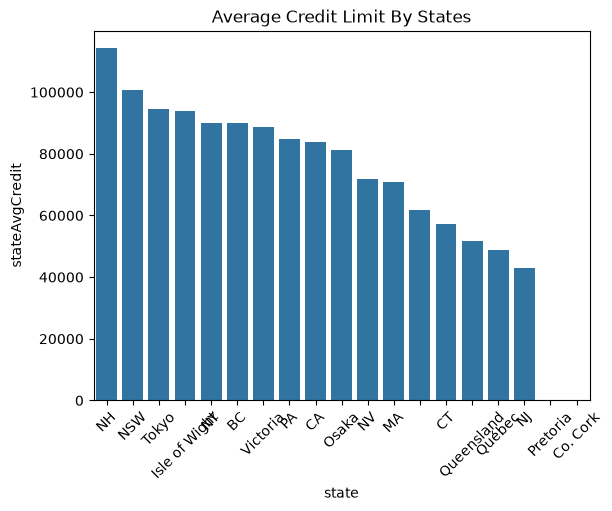

In [82]:
# Replace None with your visual code
# Produce a visual to represent the average credit limit by state
sns.barplot(
    data = stateCreditLimit,
    x= "state",
    y= "stateAvgCredit"
)
plt.title("Average Credit Limit By States")
plt.xticks(rotation=45)
plt.show()


### Step 5: Top Customers - Visual Required
The company is approaching its 10 year anniversary and wants to acknowledge and thank its top customers with personalized communication. They have asked you to determine the top 10 customers based on the total amount of payments made, making sure to return the customer name for clarity. 

Execute a SQl query that returns the information required to address this ask.


In [83]:
# Replace None with your code
#

topCustomers = pd.read_sql("""
SELECT c.customerNUmber, c.customerName, CAST(SUM(od.quantityOrdered * od.priceEach) AS REAL) AS totalOrders
    FROM customers c
    JOIN orders o on c.customerNUmber = o.customerNUmber
    JOIN orderDetails od on o.orderNUmber = od.orderNUmber
    GROUP BY c.customerNumber
    ORDER BY totalOrders DESC
    LIMIT 10
    
""", conn)

topCustomers

,customerNumber,customerName,totalOrders
0,141,Euro+ Shopping Channel,820689.54
1,124,Mini Gifts Distributors Ltd.,591827.34
2,114,"Australian Collectors, Co.",180585.07
3,151,Muscle Machine Inc,177913.95
4,119,La Rochelle Gifts,158573.12
5,148,"Dragon Souveniers, Ltd.",156251.03
6,323,"Down Under Souveniers, Inc",154622.08
7,131,Land of Toys Inc.,149085.15
8,187,"AV Stores, Co.",148410.09
9,450,The Sharp Gifts Warehouse,143536.27


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

<function matplotlib.pyplot.show(close=None, block=None)>

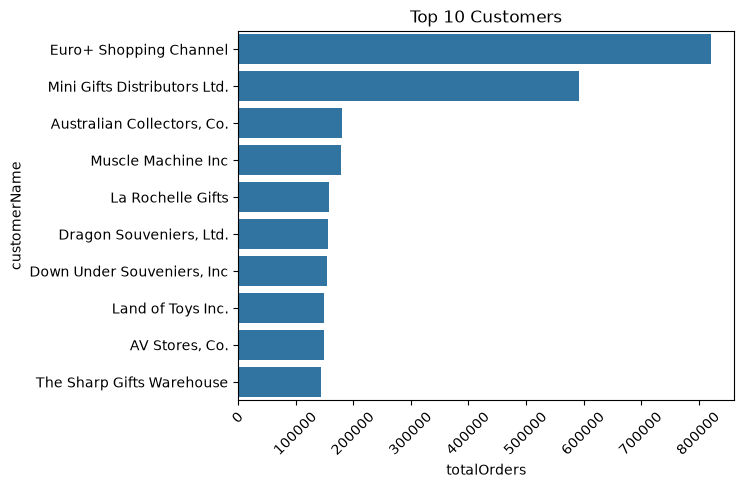

In [84]:
# Replace None with your visual code
# Produce a visual to represent the top ten customers in terms of total payments
sns.barplot(
    data = topCustomers,
    y= "customerName",
    x= "totalOrders"
)

plt.title("Top 10 Customers")
plt.xticks(rotation=45)
plt.show

### Step 6: Top Customer + Product Quantities
The product team is running an analysis on popular and common products sold to each customer in order to try and determine what new products they should be looking at to include in their catalog. This data will also be used by individual sales reps to recommend similar products to each customer next time they place an order. 

They have asked you to query information, for each customer, about any product they have purchased 10 or more units of. In addition they would like the full set of data to be sorted in ascending order by the total amount purchased.

Execute a SQl query that returns the information required to address this ask.

Hint: For this one, you'll need to make use of HAVING, GROUP BY, and ORDER BY — make sure you get the order of them correct!

In [85]:
# Replace None with you code
pd.read_sql("""
SELECT c.customerNumber, c.customerName, p.productCode, p.productName, od.quantityOrdered, CAST(SUM(od.quantityOrdered * od.priceEach) AS REAL) AS totalAmount 
    FROM customers c
    JOIN orders o ON c.customerNumber = o.customerNumber
    JOIN orderDetails od on o.orderNumber = od.orderNumber
    JOIN products p on od.productCode = p.productCode
    GROUP BY c.customerNumber, c.customerName, p.productCode
    HAVING SUM(od.quantityOrdered >= 10)
    ORDER BY c.customerName, totalAmount ASC
    
""", conn)

,customerNumber,customerName,productCode,productName,quantityOrdered,totalAmount
0,187,"AV Stores, Co.",S18_2957,1934 Ford V8 Coupe,26,1380.34
1,187,"AV Stores, Co.",S18_1367,1936 Mercedes-Benz 500K Special Roadster,27,1382.67
2,187,"AV Stores, Co.",S72_3212,Pont Yacht,35,1681.75
3,187,"AV Stores, Co.",S50_1514,1962 City of Detroit Streetcar,34,1752.70
4,187,"AV Stores, Co.",S24_1937,1939 Chevrolet Deluxe Coupe,20,1921.75
...,...,...,...,...,...,...
2527,240,giftsbymail.co.uk,S700_3505,The Titanic,48,4135.20
2528,240,giftsbymail.co.uk,S10_4757,1972 Alfa Romeo GTA,33,4173.84
2529,240,giftsbymail.co.uk,S18_3856,1941 Chevrolet Special Deluxe Cabriolet,47,4229.53
2530,240,giftsbymail.co.uk,S18_3259,Collectable Wooden Train,48,4694.88


### Step 7: Product Analysis - Visual Required

The product team is looking into the demand across its different product lines. They are conducting a comprehensive review of its product portfolio and inventory management strategies. You have been asked to query data pertaining to each different product line, that contains the total quantity ordered and the total number of products for each respective product line. By examining the number of products and total quantity ordered for each product line, the company aims to:
1. Optimize product mix:
    - Identify which product lines have the most diverse offerings (high number of products)
    - Determine which lines are most popular (high total quantity ordered)
    - Compare if lines with more products necessarily lead to more orders
2. Improve inventory management:
    - Adjust stock levels based on the popularity of each product line
    - Identify potential overstocking in lines with low order quantities
    - Ensure adequate variety in high-performing product lines
3. Adjust marketing strategy:
    - Focus promotional efforts on product lines with high potential (many products but lower order quantities)
    - Capitalize on the popularity of high-performing lines in marketing campaigns
4. Advise Product development:
    - Invest in expanding product ranges for lines with high order quantities
    - Consider phasing out or revamping product lines with low numbers of products and low order quantities

Hint: Think about how you can and might have to utilize SQL DISTINCT statement

Execute a SQl query that returns the information required to address this ask.

In [117]:
# Replace None with your code
product_line_analysis = pd.read_sql("""
SELECT p.productLine, COUNT(DISTINCT p.productCode) AS numberOfProducts, SUM(od.quantityOrdered) AS totalQuantityOrdered
    FROM products p
    JOIN orderDetails od on od.productCode = p.productCode
    JOIN orders o on od.orderNumber = o.orderNumber
    GROUP BY p.productLine
    ORDER BY numberOfProducts DESC, totalQuantityOrdered DESC
""", conn)

product_line_analysis

,productLine,numberOfProducts,totalQuantityOrdered
0,Classic Cars,37,35582
1,Vintage Cars,24,22933
2,Motorcycles,13,12778
3,Planes,12,11872
4,Trucks and Buses,11,11001
5,Ships,9,8532
6,Trains,3,2818


Once you have the information returned in a dataframe, select an appropriate visualization to represent the relationship between total quantity ordered and the number of products in order to perform a preliminary investigation into the question of if more products lead to more orders. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

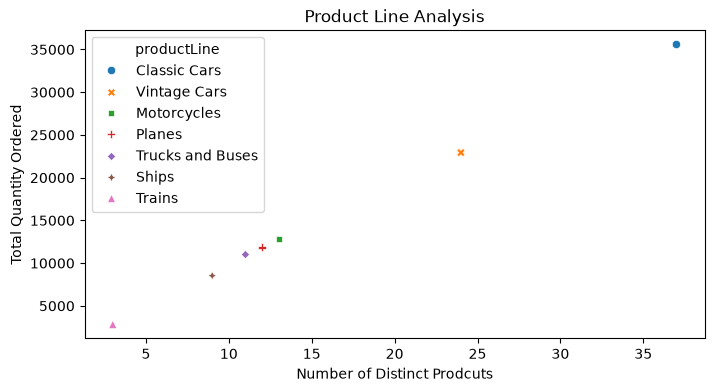

In [127]:
# Replace None with your visual code
# Produce a visual to represent the the relation between number of products and the total amount ordered

fig, ax = plt.subplots(figsize = (8, 4))
ax = sns.scatterplot(data = product_line_analysis,
                          x= "numberOfProducts",
                          y = "totalQuantityOrdered",
                          style = "productLine",
                          hue = "productLine"
                          )
ax.set_xlabel("Number of Distinct Prodcuts")
ax.set_ylabel("Total Quantity Ordered")
ax.set_title("Product Line Analysis")
plt.show()

## Reflection Question:

Please explain your choice in the type of visual you used in order to highlight and represent the data from the above query. In a non-technical manner explain why that chart type makes sense for the information being conveyed. What does this visual convey in the context of the question it was asked for?

## Type your answer in markdown here!

My choice of Using a Scatterplot is because we are comparing the relationship between two numerical values. I also set the style to the productLine to show which product line is being referred to in the plots.
The visual clearly conveys that a higher number of distinct products in a product Line results to Higher Orders

### Step 8: Remote Offices
Upper management is considering a shift to hybrid and remote work for certain locations and roles. They have tasked you with providing them data about employees who work in any office that has fewer than 5 total employees so they can better understand how to support those employees remotely when offices are shut down. 

Be sure to include information about the employees job and supervisor so management can adjust everyone to remote work properly.

Hint: Utilize a subquery to find the relevant offices

Execute a SQl query that returns the information required to address this ask.

In [167]:
# Replace None with your code


#SUBQUERY
pd.read_sql("""
SELECT * 
    FROM offices o
    JOIN employees e ON o.officeCode = e.officeCode
    GROUP BY o.officeCode
    HAVING COUNT(e.employeeNumber) < 5
""", conn)






#MAINQUERY
pd.read_sql("""
SELECT e.employeeNumber, e.firstName, e.lastName, e.officeCode, e.jobTitle, e.reportsTo, CONCAT(em.firstName, " ", em.lastName) AS supervisor
    FROM employees e
    LEFT JOIN employees em ON e.reportsTo = em.employeeNumber
    ORDER BY e.employeeNumber ASC
""", conn)



#NESTEDQUERY
pd.read_sql("""
SELECT e.employeeNumber, e.firstName, e.lastName, e.officeCode, e.jobTitle, e.reportsTo, CONCAT(em.firstName, " ", em.lastName) AS supervisor
    FROM employees e 
    LEFT JOIN employees em ON e.reportsTo = em.employeeNumber
    WHERE e.officeCode IN(
    SELECT o.officeCode 
    FROM offices o
    JOIN employees e ON o.officeCode = e.officeCode
    GROUP BY o.officeCode
    HAVING COUNT(e.employeeNumber) < 5
    )
    ORDER BY e.officeCode ASC
""", conn)

,employeeNumber,firstName,lastName,officeCode,jobTitle,reportsTo,supervisor
0,1188,Julie,Firrelli,2,Sales Rep,1143,Anthony Bow
1,1216,Steve,Patterson,2,Sales Rep,1143,Anthony Bow
2,1286,Foon Yue,Tseng,3,Sales Rep,1143,Anthony Bow
3,1323,George,Vanauf,3,Sales Rep,1143,Anthony Bow
4,1621,Mami,Nishi,5,Sales Rep,1056,Mary Patterson
5,1625,Yoshimi,Kato,5,Sales Rep,1621,Mami Nishi
6,1088,William,Patterson,6,Sales Manager (APAC),1056,Mary Patterson
7,1611,Andy,Fixter,6,Sales Rep,1088,William Patterson
8,1612,Peter,Marsh,6,Sales Rep,1088,William Patterson
9,1619,Tom,King,6,Sales Rep,1088,William Patterson


## Reflection Question:

Describe how you decided on the subquery that you used in the query above? This answer can be technically in nature, describing your thought process in how the main query is utilizing the subquery to return the correct data.

## Type your answer in markdown here!


In my Inner/Subquery, I looked for offices which have less than 5 total employees
In my outer/main query, I diplayed the required information such as employee job and supervisor

### Step 9: Close the Connection

Now that you are finished executing your queries and retrieving the required information you always want to make sure to close the connection to your database.

In [168]:
# Replace None with your code
conn.close()

### End of Guided Section
In this initial portion of the assessment, you produced several data queries and visualizations for a model company, mainly focused around its customer and product data. You wrote and engineered specific SQL queries to address pertinent questions and asks from the company. Along the way, you utilized many of the major concepts and keywords associated with SQL SELECT queries: FROM, WHERE, GROUP BY, HAVING, ORDER BY, JOIN, SUM, COUNT, and AVG.

## Part 2: Exploratory Analysis with SQL
In this open-ended exploratory section, you will analyze real-world data from the movie industry. As a data analyst, you have the freedom to investigate questions and topics that intrigue you within this dataset. The database schema and Entity-Relationship Diagram (ERD) are provided below for your reference. A general overview and instructions are also provided below.

In [169]:
# Run this cell without changes
import zipfile

zip_file_path = 'im.db.zip'
extract_to_path = './'

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to_path)

# Connection
conn4 = sqlite3.connect('im.db')

# Schema
schema_df = pd.read_sql("""
SElECT * FROM sqlite_master                        
""", conn4)
schema_df

,type,name,tbl_name,rootpage,sql
0,table,movie_basics,movie_basics,2,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
1,table,directors,directors,3,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
2,table,known_for,known_for,4,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
3,table,movie_akas,movie_akas,5,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
4,table,movie_ratings,movie_ratings,6,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,table,persons,persons,7,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,table,principals,principals,8,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,table,writers,writers,9,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


## The Data

![movie ERD](images/movie_data_erd.jpeg)
### Database Content:

- Source: IMDB
- Time Range: Movies released between 2010 and 2019
- Note: Exclude any movies with a start_year after 2019 as this data is not current or accurate

Available Data Categories:
- Genre
- Runtime
- Personnel (writers, directors, actors)
- Movie ratings

### Objectives:

Initial Exploration:
- Use SQL in combination with Pandas to explore the database
- Identify interesting trends, patterns, or relationships in the data

Business Question Formulation:
- Develop at least one substantial business question for deeper analysis
- Ensure the question is relevant, specific, and can be addressed with the available data

Data Cleaning Assessment:
- Identify potential data cleaning tasks necessary for your deeper analysis
- Note: You are not required to perform the cleaning, only to recognize and list the necessary tasks

Null Value Handling:
- Be aware that the dataset contains null values in certain fields
- Exclude these null values from your exploration
- Do not attempt to input or fill in missing information

### Deliverables:

You need to produce a short slide presentation (3-5 slides) that highlights the three key deliverables below. Utilize a data visualization to support the second deliverable.

1. A summary of your initial data exploration findings
    - Can be bulleted or sentence form
2. At least one well-formulated business question for further analysis
    - Should stem from a relevant trend or pattern your initial exploration identified
3. A list of potential data cleaning tasks identified during your exploration
    - This can and should include things like data normalization/standardization and null handling

Tips for Success:

Begin with broad exploratory queries to understand the data's scope and content. Then focus on honing in on interesting relationships between different data categories. Consider industry trends, audience preferences, or financial aspects when formulating your business question. Pay attention to data quality issues, inconsistencies, or limitations that might affect your analysis. Remember, the goal is to demonstrate your analytical thinking and ability to derive meaningful insights from complex datasets. Good luck with your exploration!

NOTE: You do not need to explore every aspect of this database. Find something that you think is interesting or relevant about the data and focus your exploration there.

In [192]:
# Begin your code here
# DIRECTORS TABLE
directors_df = pd.read_sql("""
SELECT *
    FROM directors

""", conn4)

print("\n\nDF SHAPE\n")
print(directors_df.shape)

print("\n\nDF DESCRIBE\n")
print(directors_df.describe())

print("\n\nDF INFO\n")
print(directors_df.info())

print("\n\nDF HEAD\n")

directors_df.head()






DF SHAPE

(291174, 2)


DF DESCRIBE

         movie_id  person_id
count      291174     291174
unique     140417     109253
top     tt4050462  nm6935209
freq         3818        238


DF INFO

<class 'pandas.DataFrame'>
RangeIndex: 291174 entries, 0 to 291173
Data columns (total 2 columns):
 #   Column     Non-Null Count   Dtype
---  ------     --------------   -----
 0   movie_id   291174 non-null  str  
 1   person_id  291174 non-null  str  
dtypes: str(2)
memory usage: 9.5 MB
None


DF HEAD



,movie_id,person_id
0,tt0285252,nm0899854
1,tt0462036,nm1940585
2,tt0835418,nm0151540
3,tt0835418,nm0151540
4,tt0878654,nm0089502


In [196]:
#KNOWN FOR TABLE

known_for_df = pd.read_sql("""
SELECT *
    FROM known_for

""", conn4)

print("\n\nDF SHAPE\n")
print(known_for_df.shape)

print("\n\nDF DESCRIBE\n")
print(known_for_df.describe())

print("\n\nDF INFO\n")
print(known_for_df.info())

print("\n\nDF HEAD\n")

known_for_df.head()





DF SHAPE

(1638260, 2)


DF DESCRIBE

        person_id   movie_id
count     1638260    1638260
unique     576444     514781
top     nm1202937  tt0806910
freq            6        633


DF INFO

<class 'pandas.DataFrame'>
RangeIndex: 1638260 entries, 0 to 1638259
Data columns (total 2 columns):
 #   Column     Non-Null Count    Dtype
---  ------     --------------    -----
 0   person_id  1638260 non-null  str  
 1   movie_id   1638260 non-null  str  
dtypes: str(2)
memory usage: 53.1 MB
None


DF HEAD



,person_id,movie_id
0,nm0061671,tt0837562
1,nm0061671,tt2398241
2,nm0061671,tt0844471
3,nm0061671,tt0118553
4,nm0061865,tt0896534


In [198]:
#MOVIE_AKAS TABLE

movie_akas_df = pd.read_sql("""
SELECT *
    FROM movie_akas

""", conn4)

print("\n\nDF SHAPE\n")
print(movie_akas_df.shape)

print("\n\nDF DESCRIBE\n")
print(movie_akas_df.describe())

print("\n\nDF INFO\n")
print(movie_akas_df.info())

print("\n\nDF HEAD\n")

movie_akas_df.head()




DF SHAPE

(331703, 8)


DF DESCRIBE

            ordering  is_original_title
count  331703.000000      331678.000000
mean        5.125872           0.134769
std         6.706664           0.341477
min         1.000000           0.000000
25%         1.000000           0.000000
50%         2.000000           0.000000
75%         6.000000           0.000000
max        61.000000           1.000000


DF INFO

<class 'pandas.DataFrame'>
RangeIndex: 331703 entries, 0 to 331702
Data columns (total 8 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   movie_id           331703 non-null  str    
 1   ordering           331703 non-null  int64  
 2   title              331703 non-null  str    
 3   region             278410 non-null  str    
 4   language           41715 non-null   str    
 5   types              168447 non-null  str    
 6   attributes         14925 non-null   str    
 7   is_original_title  331678 non-null  float64
d

,movie_id,ordering,title,region,language,types,attributes,is_original_title
0,tt0369610,10,Джурасик свят,BG,bg,NaN,NaN,0.0
1,tt0369610,11,Jurashikku warudo,JP,NaN,imdbDisplay,NaN,0.0
2,tt0369610,12,Jurassic World: O Mundo dos Dinossauros,BR,NaN,imdbDisplay,NaN,0.0
3,tt0369610,13,O Mundo dos Dinossauros,BR,NaN,NaN,short title,0.0
4,tt0369610,14,Jurassic World,FR,NaN,imdbDisplay,NaN,0.0


In [199]:
#MOVIE_BASICS TABLE

movie_basics_df = pd.read_sql("""
SELECT *
    FROM movie_basics

""", conn4)

print("\n\nDF SHAPE\n")
print(movie_basics_df.shape)

print("\n\nDF DESCRIBE\n")
print(movie_basics_df.describe())

print("\n\nDF INFO\n")
print(movie_basics_df.info())

print("\n\nDF HEAD\n")

movie_basics_df.head()



DF SHAPE

(146144, 6)


DF DESCRIBE

          start_year  runtime_minutes
count  146144.000000    114405.000000
mean     2014.621798        86.187247
std         2.733583       166.360590
min      2010.000000         1.000000
25%      2012.000000        70.000000
50%      2015.000000        87.000000
75%      2017.000000        99.000000
max      2115.000000     51420.000000


DF INFO

<class 'pandas.DataFrame'>
RangeIndex: 146144 entries, 0 to 146143
Data columns (total 6 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   movie_id         146144 non-null  str    
 1   primary_title    146144 non-null  str    
 2   original_title   146123 non-null  str    
 3   start_year       146144 non-null  int64  
 4   runtime_minutes  114405 non-null  float64
 5   genres           140736 non-null  str    
dtypes: float64(1), int64(1), str(4)
memory usage: 14.8 MB
None


DF HEAD



,movie_id,primary_title,original_title,start_year,runtime_minutes,genres
0,tt0063540,Sunghursh,Sunghursh,2013,175.0,"Action,Crime,Drama"
1,tt0066787,One Day Before the Rainy Season,Ashad Ka Ek Din,2019,114.0,"Biography,Drama"
2,tt0069049,The Other Side of the Wind,The Other Side of the Wind,2018,122.0,Drama
3,tt0069204,Sabse Bada Sukh,Sabse Bada Sukh,2018,NaN,"Comedy,Drama"
4,tt0100275,The Wandering Soap Opera,La Telenovela Errante,2017,80.0,"Comedy,Drama,Fantasy"


In [218]:
#MOVIE_RATINGS TABLE

movie_ratings_df = pd.read_sql("""
SELECT *
    FROM movie_ratings

""", conn4)

print("\n\nDF SHAPE\n")
print(movie_ratings_df.shape)

print("\n\nDF DESCRIBE\n")
print(movie_ratings_df.describe())

print("\n\nDF INFO\n")
print(movie_ratings_df.info())

print("\nDF HEAD\n")

movie_ratings_df.head()



DF SHAPE

(73856, 3)


DF DESCRIBE

       averagerating      numvotes
count   73856.000000  7.385600e+04
mean        6.332729  3.523662e+03
std         1.474978  3.029402e+04
min         1.000000  5.000000e+00
25%         5.500000  1.400000e+01
50%         6.500000  4.900000e+01
75%         7.400000  2.820000e+02
max        10.000000  1.841066e+06


DF INFO

<class 'pandas.DataFrame'>
RangeIndex: 73856 entries, 0 to 73855
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   movie_id       73856 non-null  str    
 1   averagerating  73856 non-null  float64
 2   numvotes       73856 non-null  int64  
dtypes: float64(1), int64(1), str(1)
memory usage: 2.3 MB
None

DF HEAD



,movie_id,averagerating,numvotes
0,tt10356526,8.3,31
1,tt10384606,8.9,559
2,tt1042974,6.4,20
3,tt1043726,4.2,50352
4,tt1060240,6.5,21


In [202]:
#PERSONS TABLE

persons_df = pd.read_sql("""
SELECT *
    FROM persons

""", conn4)

print("\n\nDF SHAPE\n")
print(persons_df.shape)

print("\n\nDF DESCRIBE\n")
print(persons_df.describe())

print("\n\nDF INFO\n")
print(persons_df.info())

print("\n\nDF HEAD\n")

persons_df.head()



DF SHAPE

(606648, 5)


DF DESCRIBE

         birth_year   death_year
count  82736.000000  6783.000000
mean    1967.043826  2000.523367
std       22.122190    43.951530
min        1.000000    17.000000
25%     1957.000000  2001.000000
50%     1971.000000  2013.000000
75%     1981.000000  2016.000000
max     2014.000000  2019.000000


DF INFO

<class 'pandas.DataFrame'>
RangeIndex: 606648 entries, 0 to 606647
Data columns (total 5 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   person_id           606648 non-null  str    
 1   primary_name        606648 non-null  str    
 2   birth_year          82736 non-null   float64
 3   death_year          6783 non-null    float64
 4   primary_profession  555308 non-null  str    
dtypes: float64(2), str(3)
memory usage: 46.2 MB
None


DF HEAD



,person_id,primary_name,birth_year,death_year,primary_profession
0,nm0061671,Mary Ellen Bauder,NaN,NaN,"miscellaneous,production_manager,producer"
1,nm0061865,Joseph Bauer,NaN,NaN,"composer,music_department,sound_department"
2,nm0062070,Bruce Baum,NaN,NaN,"miscellaneous,actor,writer"
3,nm0062195,Axel Baumann,NaN,NaN,"camera_department,cinematographer,art_department"
4,nm0062798,Pete Baxter,NaN,NaN,"production_designer,art_department,set_decorator"


In [203]:
#principals TABLE

principals_df = pd.read_sql("""
SELECT *
    FROM principals

""", conn4)

print("\n\nDF SHAPE\n")
print(principals_df.shape)

print("\n\nDF DESCRIBE\n")
print(principals_df.describe())

print("\n\nDF INFO\n")
print(principals_df.info())

print("\n\nDF HEAD\n")

principals_df.head()



DF SHAPE

(1028186, 6)


DF DESCRIBE

           ordering
count  1.028186e+06
mean   4.739847e+00
std    2.747446e+00
min    1.000000e+00
25%    2.000000e+00
50%    4.000000e+00
75%    7.000000e+00
max    1.000000e+01


DF INFO

<class 'pandas.DataFrame'>
RangeIndex: 1028186 entries, 0 to 1028185
Data columns (total 6 columns):
 #   Column      Non-Null Count    Dtype
---  ------      --------------    -----
 0   movie_id    1028186 non-null  str  
 1   ordering    1028186 non-null  int64
 2   person_id   1028186 non-null  str  
 3   category    1028186 non-null  str  
 4   job         177684 non-null   str  
 5   characters  393360 non-null   str  
dtypes: int64(1), str(5)
memory usage: 78.9 MB
None


DF HEAD



,movie_id,ordering,person_id,category,job,characters
0,tt0111414,1,nm0246005,actor,NaN,"[""The Man""]"
1,tt0111414,2,nm0398271,director,NaN,NaN
2,tt0111414,3,nm3739909,producer,producer,NaN
3,tt0323808,10,nm0059247,editor,NaN,NaN
4,tt0323808,1,nm3579312,actress,NaN,"[""Beth Boothby""]"


In [204]:
#WRITERS TABLE

writers_df = pd.read_sql("""
SELECT *
    FROM writers

""", conn4)

print("\n\nDF SHAPE\n")
print(writers_df.shape)

print("\n\nDF DESCRIBE\n")
print(writers_df.describe())

print("\n\nDF INFO\n")
print(writers_df.info())

print("\n\nDF HEAD\n")

writers_df.head()



DF SHAPE

(255873, 2)


DF DESCRIBE

         movie_id  person_id
count      255873     255873
unique     110261     122576
top     tt4050462  nm6935209
freq         3818        543


DF INFO

<class 'pandas.DataFrame'>
RangeIndex: 255873 entries, 0 to 255872
Data columns (total 2 columns):
 #   Column     Non-Null Count   Dtype
---  ------     --------------   -----
 0   movie_id   255873 non-null  str  
 1   person_id  255873 non-null  str  
dtypes: str(2)
memory usage: 8.3 MB
None


DF HEAD



,movie_id,person_id
0,tt0285252,nm0899854
1,tt0438973,nm0175726
2,tt0438973,nm1802864
3,tt0462036,nm1940585
4,tt0835418,nm0310087


In [ ]:
#AVERAGE MOVIE RATINGS BASED ON GENRE
pd.read_sql("""
SELECT *, AVG(averagerating) AS averageRating
    FROM movie_basics mb
    JOIN movie_ratings mv ON mb.movie_id = mv.movie_id
    GROUP BY genres
    ORDER BY averageRating DESC
""", conn4)

,movie_id,primary_title,original_title,start_year,runtime_minutes,genres,movie_id,averagerating,numvotes,averageRating
0,tt1740810,Love on a Leash,Love on a Leash,2010,10.0,"Documentary,Family,Romance",tt1740810,9.7,25,8.160000
1,tt10146728,Foosballers,Foosballers,2019,NaN,"Comedy,Documentary,Sport",tt10146728,9.7,22,7.925000
2,tt4135932,Lost Conquest,Lost Conquest,2015,70.0,"Comedy,Documentary,Fantasy",tt4135932,9.4,5,9.400000
3,tt3856476,Sunakali,Sunakali,2017,59.0,"Documentary,Family,Musical",tt3856476,9.3,19,9.300000
4,tt5903964,The Long Count Teaser,The Long Count Teaser,2016,NaN,"History,Sport",tt5903964,9.2,5,9.200000
...,...,...,...,...,...,...,...,...,...,...
919,tt0249516,Foodfight!,Foodfight!,2012,91.0,"Action,Animation,Comedy",tt0249516,1.9,8248,6.471429
920,tt0937353,The Devil's Flower,Tsvetok dyavola,2010,90.0,"Mystery,Romance",tt0937353,1.7,201,6.150000
921,tt5161302,Eyal Hirrifah,Eyal Hirrifah,2015,101.0,"Comedy,Musical,Sport",tt5161302,1.4,28,1.400000
922,tt1865374,Futures Past,Futures Past,2012,120.0,"Action,Biography,History",tt1865374,1.3,33,5.400000


In [216]:
#AVERAGE MOVIE RATINGS BASED ON START_YEAR
pd.read_sql("""
SELECT *, AVG(averagerating) AS averageRating
    FROM movie_basics mb
    JOIN movie_ratings mv ON mb.movie_id = mv.movie_id
    GROUP BY start_year
    ORDER BY start_year ASC
""", conn4)

,movie_id,primary_title,original_title,start_year,runtime_minutes,genres,movie_id,averagerating,numvotes,averageRating
0,tt0146592,Pál Adrienn,Pál Adrienn,2010,136.0,Drama,tt0146592,6.8,451,6.259585
1,tt0176694,The Tragedy of Man,Az ember tragédiája,2011,160.0,"Animation,Drama,History",tt0176694,7.8,584,6.290134
2,tt0249516,Foodfight!,Foodfight!,2012,91.0,"Action,Animation,Comedy",tt0249516,1.9,8248,6.297057
3,tt0063540,Sunghursh,Sunghursh,2013,175.0,"Action,Crime,Drama",tt0063540,7.0,77,6.287259
4,tt0329539,Rice Girl,Rice Girl,2014,95.0,"Adventure,Comedy,Romance",tt0329539,6.1,73,6.319806
5,tt0283440,Short Time Heroes,Kurzzeithelden,2015,45.0,Sci-Fi,tt0283440,6.6,16,6.265894
6,tt0315642,Wazir,Wazir,2016,103.0,"Action,Crime,Drama",tt0315642,7.1,15378,6.347300
7,tt0100275,The Wandering Soap Opera,La Telenovela Errante,2017,80.0,"Comedy,Drama,Fantasy",tt0100275,6.5,119,6.397624
8,tt0069049,The Other Side of the Wind,The Other Side of the Wind,2018,122.0,Drama,tt0069049,6.9,4517,6.415599
9,tt0066787,One Day Before the Rainy Season,Ashad Ka Ek Din,2019,114.0,"Biography,Drama",tt0066787,7.2,43,6.703578


In [217]:
#NUMBER OF MOVIES RELEASED EVERY YEAR
pd.read_sql("""
SELECT *, COUNT(movie_id) AS NumberofMovies
    FROM movie_basics
    WHERE start_year <= 2019
    GROUP BY start_year
    ORDER BY start_year ASC
""", conn4)


,movie_id,primary_title,original_title,start_year,runtime_minutes,genres,NumberofMovies
0,tt0146592,Pál Adrienn,Pál Adrienn,2010,136.0,Drama,11849
1,tt0176694,The Tragedy of Man,Az ember tragédiája,2011,160.0,"Animation,Drama,History",12900
2,tt0139613,O Silêncio,O Silêncio,2012,NaN,"Documentary,History",13787
3,tt0063540,Sunghursh,Sunghursh,2013,175.0,"Action,Crime,Drama",14709
4,tt0329539,Rice Girl,Rice Girl,2014,95.0,"Adventure,Comedy,Romance",15589
5,tt0283440,Short Time Heroes,Kurzzeithelden,2015,45.0,Sci-Fi,16243
6,tt0315642,Wazir,Wazir,2016,103.0,"Action,Crime,Drama",17272
7,tt0100275,The Wandering Soap Opera,La Telenovela Errante,2017,80.0,"Comedy,Drama,Fantasy",17504
8,tt0069049,The Other Side of the Wind,The Other Side of the Wind,2018,122.0,Drama,16849
9,tt0066787,One Day Before the Rainy Season,Ashad Ka Ek Din,2019,114.0,"Biography,Drama",8379


Data Cleaning Assessment

Identify potential data cleaning tasks necessary for your deeper analysis.
1. Dropping of data with too many null values
2. Stripping empty spaces before and after text
3. Converting some columns to their proper data types such as year to date from integer
4. Normalizing Data to only select the ones whose names are in English